# Silage or grain, from space: start here

- This tool makes a **silage or grain call for every corn field, every year**, from free public satellite imagery (Sentinel-1, Sentinel-2).
- Today the Census of Agriculture gives **one silage number per county, once every five years**.
- Two models are shown. The **Maryland-only model** is a satellite time-series model (Presto) fine-tuned on BARC Maryland farm records, 2017-2020. The **county-share model** is the same model that also learns from the published 2022 Census county silage shares in 163 counties; it uses no field labels outside Maryland.
- Everything below is computed in this notebook from the saved prediction files. The outputs are saved, so nothing needs to be run.

Interactive map: open `classifier/atlas/atlas.html` (in JupyterLab click 'Trust HTML' at the top of the file).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import rankdata, spearmanr

R = "classifier/counties/national/results_final/"
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.titlesize": 10.5})
CMAP = "viridis"
MODELS = {"Maryland-only model": "p_barc", "County-share model": "p_llp"}

fields = pd.read_csv(R + "field_predictions.csv")
fields["y"] = (fields["label"] == "Silage").astype(int)
counties = pd.read_csv(R + "county_predictions.csv", dtype={"fips": str})
test = pd.read_csv(R + "test_county_predictions.csv", dtype={"fips": str})
blocks = pd.read_csv(R + "block_predictions.csv", dtype={"fips": str})
squares = pd.read_csv("classifier/counties/national/county_squares.csv",
                      usecols=["field_id", "lon", "lat", "fips"], dtype={"fips": str})
prior = pd.read_csv(R + "census_prior/census_prior_counties.csv", dtype={"fips": str})

def confusion(y, p):
    # silage is the positive class; a field is called silage at p >= 0.5
    y, c = np.asarray(y).astype(bool), np.asarray(p) >= 0.5
    return (c & y).sum(), (~c & y).sum(), (c & ~y).sum(), (~c & ~y).sum()   # tp, fn, fp, tn

def auc(y, p):
    y = np.asarray(y).astype(bool); r = rankdata(p); n1, n0 = y.sum(), (~y).sum()
    return (r[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

def kappa(tp, fn, fp, tn):
    n = tp + fn + fp + tn; po = (tp + tn) / n
    pe = ((tp + fn) * (tp + fp) + (tn + fp) * (tn + fn)) / n**2
    return (po - pe) / (1 - pe)

rows = {}
for name, col in MODELS.items():
    r = {}
    for kind, place in [("barc", "Maryland official test"), ("quebec", "Québec")]:
        d = fields[fields.kind == kind]
        tp, fn, fp, tn = confusion(d.y, d[col])
        r[f"{place}: accuracy"] = f"{tp + tn}/{len(d)} = {(tp + tn) / len(d):.3f}"
        r[f"{place}: silage recall (silage caught)"] = f"{tp}/{tp + fn} = {tp / (tp + fn):.3f}"
        if kind == "barc":
            r[f"{place}: grain precision"] = f"{tn}/{tn + fn} = {tn / (tn + fn):.3f}"
            r[f"{place}: Cohen's kappa"] = f"{kappa(tp, fn, fp, tn):.3f}"
        r[f"{place}: AUC"] = f"{auc(d.y, d[col]):.3f}"
    pred = counties["barc_called" if col == "p_barc" else "llp_oof_called"]   # share of blocks called silage
    err = pred - counties.census_share
    r["163 counties vs 2022 Census: mean absolute error"] = f"{err.abs().mean():.3f}"
    r["163 counties vs 2022 Census: bias"] = f"{err.mean():+.3f}"
    r["163 counties vs 2022 Census: Spearman"] = f"{spearmanr(pred, counties.census_share)[0]:.2f}"
    tpred = test["barc_called" if col == "p_barc" else "llp_called"]
    r["7 counties never trained on: mean absolute error"] = f"{(tpred - test.census_share).abs().mean():.3f}"
    rows[name] = r
headline = pd.DataFrame(rows)
headline

,Maryland-only model,County-share model
Maryland official test: accuracy,41/44 = 0.932,41/44 = 0.932
Maryland official test: silage recall (silage caught),11/12 = 0.917,11/12 = 0.917
Maryland official test: grain precision,30/31 = 0.968,30/31 = 0.968
Maryland official test: Cohen's kappa,0.832,0.832
Maryland official test: AUC,0.969,0.982
Québec: accuracy,1343/2245 = 0.598,1778/2245 = 0.792
Québec: silage recall (silage caught),149/1045 = 0.143,841/1045 = 0.805
Québec: AUC,0.780,0.865
163 counties vs 2022 Census: mean absolute error,0.248,0.139
163 counties vs 2022 Census: bias,-0.171,+0.004


**How to read the table.** Maryland official test = the 44 evaluation field-years of 2021-2023, years the models never saw. Québec = 2,245 field-years; no Québec label was used in training. County rows compare the share of 100 sampled corn blocks per county that the model calls silage with the 2022 Census silage share (the figures below use the mean block probability instead, which gives 0.138 and 0.231 for the 163 counties); for the county-share model each county is predicted by a model that was not trained on that county's state.

## Field calls: Maryland and Québec

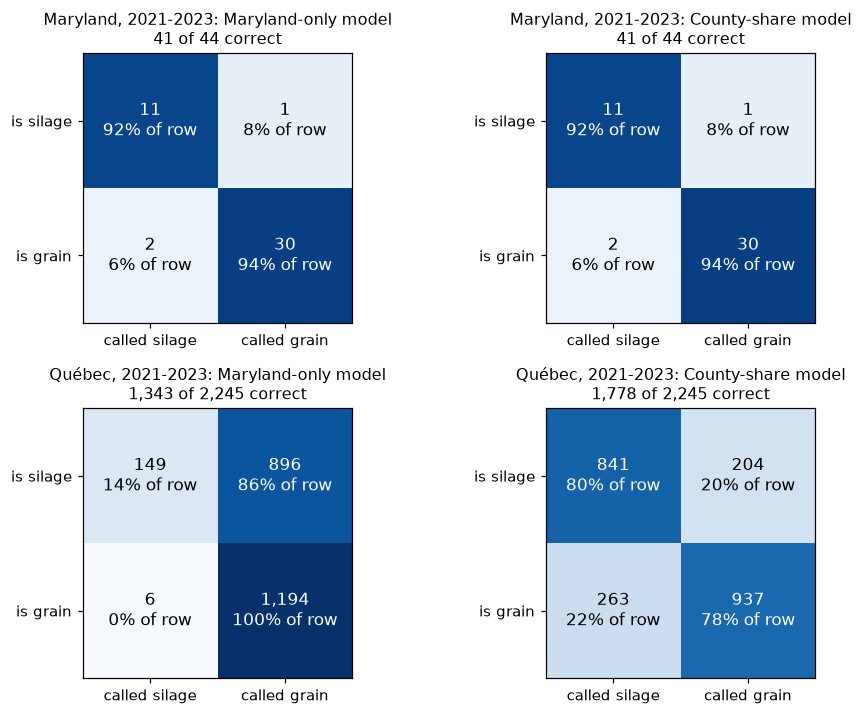

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6.6), dpi=110)
for i, (kind, place) in enumerate([("barc", "Maryland, 2021-2023"), ("quebec", "Québec, 2021-2023")]):
    d = fields[fields.kind == kind]
    for j, (name, col) in enumerate(MODELS.items()):
        tp, fn, fp, tn = confusion(d.y, d[col])
        m = np.array([[tp, fn], [fp, tn]]); ax = axes[i, j]
        share = m / m.sum(axis=1, keepdims=True)
        ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
        for a in range(2):
            for b in range(2):
                ax.text(b, a, f"{m[a, b]:,}\n{share[a, b]:.0%} of row", ha="center", va="center", fontsize=11,
                        color="white" if share[a, b] > 0.55 else "black")
        ax.set_xticks([0, 1], ["called silage", "called grain"]); ax.set_yticks([0, 1], ["is silage", "is grain"])
        ax.set_title(f"{place}: {name}\n{tp + tn:,} of {len(d):,} correct")
fig.tight_layout(); plt.show()

## County silage share: prediction and Census

Each dot is one of the 163 sampled counties, placed at the centre of its sampled corn blocks. Left: the county-share model's predicted silage share (mean block probability, out of fold by state). Right: the 2022 Census share. Same colour scale.

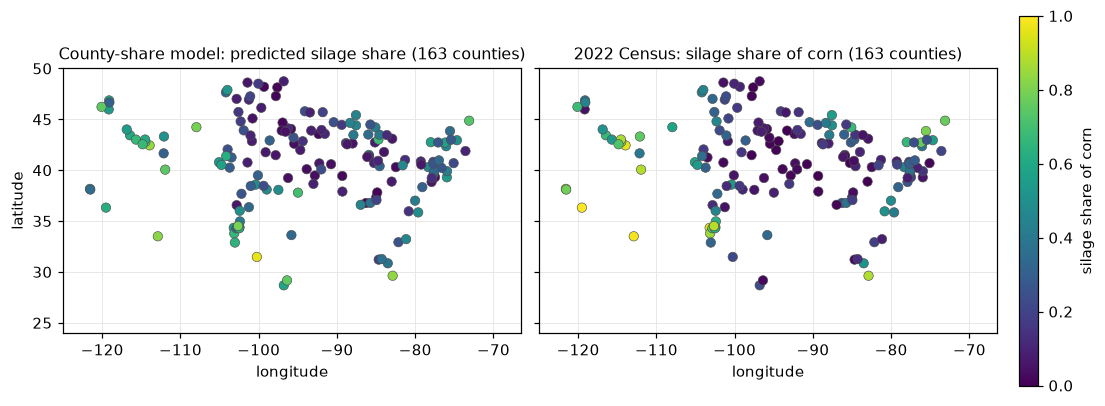

In [3]:
centre = squares.groupby("fips")[["lon", "lat"]].mean()
c = counties.join(centre, on="fips")
c = c[c.lon.between(-125, -66.5) & c.lat.between(24, 50)]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), dpi=110, sharex=True, sharey=True)
for ax, col, title in [(axes[0], "llp_oof_mean_p", "County-share model: predicted silage share"),
                       (axes[1], "census_share", "2022 Census: silage share of corn")]:
    sc = ax.scatter(c.lon, c.lat, c=c[col], cmap=CMAP, vmin=0, vmax=1, s=38, edgecolor="0.3", linewidth=0.4)
    ax.set(xlim=(-125, -66.5), ylim=(24, 50), title=f"{title} ({len(c)} counties)", xlabel="longitude")
    ax.set_aspect(1.3); ax.grid(color="0.9", linewidth=0.6); ax.set_axisbelow(True)
axes[0].set_ylabel("latitude")
fig.tight_layout()
fig.colorbar(sc, ax=axes, shrink=0.8, pad=0.02, label="silage share of corn")
plt.show()

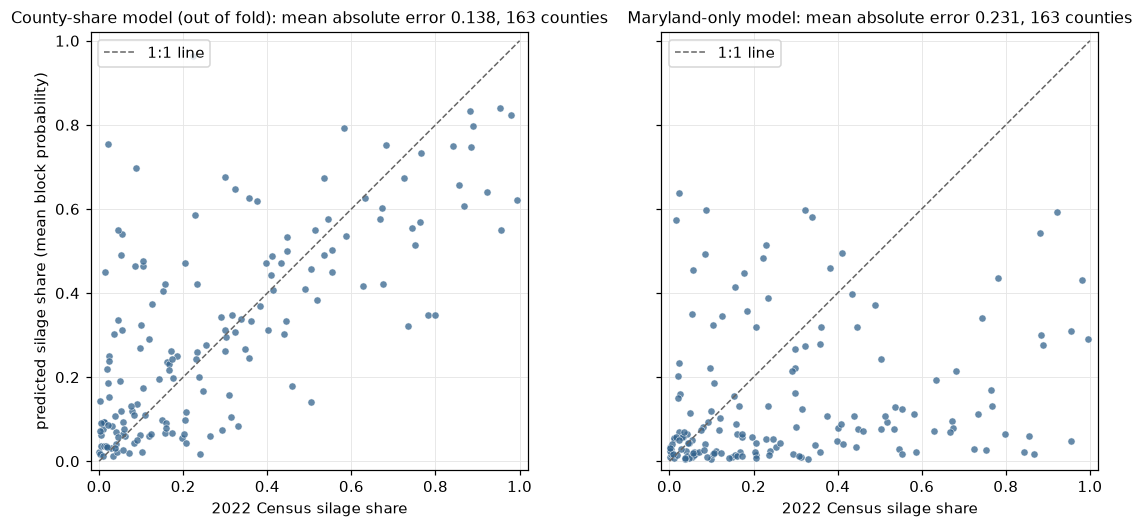

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.9), dpi=110, sharey=True)
for ax, col, name in [(axes[0], "llp_oof_mean_p", "County-share model (out of fold)"),
                      (axes[1], "barc_mean_p", "Maryland-only model")]:
    mae = (counties[col] - counties.census_share).abs().mean()
    ax.plot([0, 1], [0, 1], color="0.4", linestyle="--", linewidth=1, label="1:1 line")
    ax.scatter(counties.census_share, counties[col], s=22, color="#33638d", alpha=0.75, edgecolor="white", linewidth=0.4)
    ax.set(xlim=(-0.02, 1.02), ylim=(-0.02, 1.02), xlabel="2022 Census silage share",
           title=f"{name}: mean absolute error {mae:.3f}, {len(counties)} counties")
    ax.set_aspect("equal"); ax.grid(color="0.9", linewidth=0.6); ax.set_axisbelow(True); ax.legend(loc="upper left")
axes[0].set_ylabel("predicted silage share (mean block probability)")
fig.tight_layout(); plt.show()

## Inside two counties

The Census gives one number per county. The model gives a silage probability for each sampled 90 m corn block. Left: the county with the highest Census silage share among counties with 100 blocks. Right: the county with the lowest. Same colour scale.

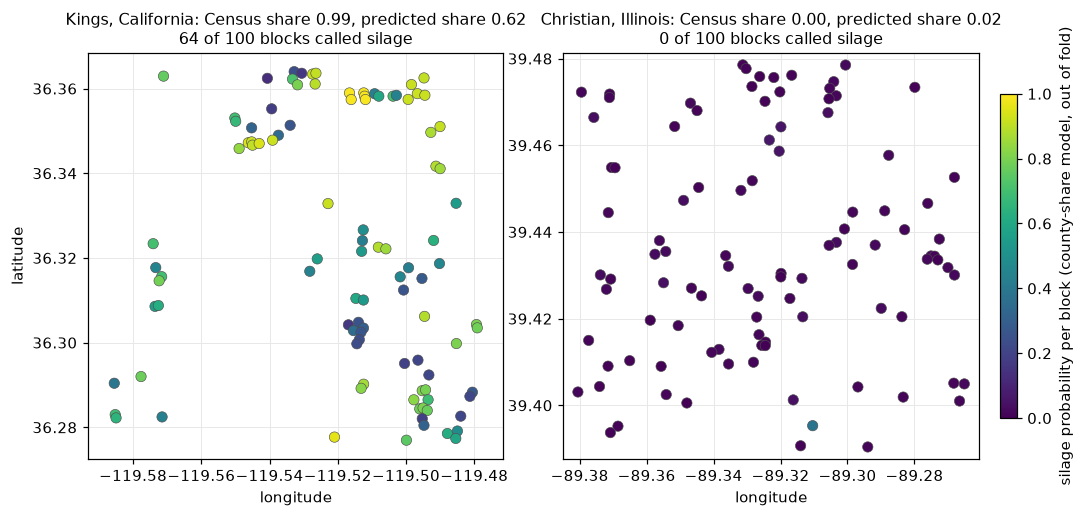

In [5]:
nat = blocks[blocks.kind == "national"].merge(squares, on=["field_id", "fips"])
n_blocks = nat.groupby("fips").size()
full = counties[counties.fips.map(n_blocks) == 100].sort_values("census_share")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), dpi=110)
axes[0].set_ylabel("latitude")
for ax, row in zip(axes, [full.iloc[-1], full.iloc[0]]):
    b = nat[nat.fips == row.fips]
    sc = ax.scatter(b.lon, b.lat, c=b.p_llp_oof, cmap=CMAP, vmin=0, vmax=1, s=46, edgecolor="0.3", linewidth=0.4)
    ax.set_title(f"{row.county}, {row.state}: Census share {row.census_share:.2f}, "
                 f"predicted share {b.p_llp_oof.mean():.2f}\n{(b.p_llp_oof >= 0.5).sum()} of {len(b)} blocks called silage")
    ax.set(xlabel="longitude"); ax.ticklabel_format(useOffset=False)
    ax.set_aspect(1 / np.cos(np.radians(b.lat.mean())), adjustable="datalim")
    ax.grid(color="0.9", linewidth=0.6); ax.set_axisbelow(True)
fig.tight_layout()
fig.colorbar(sc, ax=axes, shrink=0.8, pad=0.02, label="silage probability per block (county-share model, out of fold)")
plt.show()

In [6]:
# County totals: is the satellite estimate closer to the 2022 Census than simply reusing the previous Census?
pd.DataFrame({"mean absolute error vs 2022 Census": {
    "Previous Census reused": (prior.last_census - prior.truth).abs().mean(),
    "County-share model (out of fold)": (prior.satellite - prior.truth).abs().mean(),
    "Maryland-only model": (prior.maryland_only - prior.truth).abs().mean()}}).round(3)

,mean absolute error vs 2022 Census
Previous Census reused,0.082
County-share model (out of fold),0.138
Maryland-only model,0.231


## Limits

- **Field labels come from one farm in Maryland.** Québec is the only other place with field-level truth.
- **On Maryland the model is not significantly better than the 5-feature baseline:** 41 versus 39 of 44 field-years correct.
- **On county totals, reusing the previous Census is still closer overall:** mean absolute error 0.082 for the previous Census reused versus 0.138 for the county-share model (mean block probability; table above, 163 counties). The satellite adds the field-level and yearly detail the Census does not have.
- **Each county is represented by 100 sampled corn blocks,** not by every field.

More: `VALIDATION.md`, `classifier/README.md`